In [1]:
import numpy as np
import matplotlib.pyplot as plt


# ----------------------------------------------------------------------
# Estrategias vectorizadas sobre simulaciones
# ----------------------------------------------------------------------

class Strategy:
    def run(self, **kwargs):
        raise NotImplementedError


class AdvectionStrategy(Strategy):
    """
    Advección 1D (upwind) vectorizada sobre simulaciones.
    Acepta escalares o arrays de tamaño nsims.
    Devuelve 'concentration' de shape (nsims, nx) o (nx,) si nsims==1.
    """
    def run(self, area, volume, concentration, porosity, velocity,
            length=1000, width=500, days=30, dx=5, dt=0.1):

        area         = np.atleast_1d(np.asarray(area,         dtype=float))
        volume       = np.atleast_1d(np.asarray(volume,       dtype=float))
        concentration= np.atleast_1d(np.asarray(concentration,dtype=float))
        porosity     = np.atleast_1d(np.asarray(porosity,     dtype=float))
        velocity     = np.atleast_1d(np.asarray(velocity,     dtype=float))

        nsims = max(area.size, volume.size, concentration.size,
                    porosity.size, velocity.size)

        area          = np.broadcast_to(area,          (nsims,)).astype(float)
        volume        = np.broadcast_to(volume,        (nsims,)).astype(float)
        concentration = np.broadcast_to(concentration, (nsims,)).astype(float)
        porosity      = np.broadcast_to(porosity,      (nsims,)).astype(float)
        velocity      = np.broadcast_to(velocity,      (nsims,)).astype(float)

        x = np.arange(0, length + dx, dx)
        nx = x.size
        nt = int(days / dt) + 1

        # source por simulación
        source = concentration * volume / (area * porosity * 1000.0)   # (nsims,)
        b = (velocity * dt / dx)[:, None]                              # (nsims,1)

        C = np.zeros((nsims, nx))
        C[:, 0] = source

        for _ in range(nt):
            C_new = np.empty_like(C)
            # upwind: C_new[i] = C[i] - b*(C[i] - C[i-1])  para i>=1
            C_new[:, 1:] = C[:, 1:] - b * (C[:, 1:] - C[:, :-1])
            np.maximum(C_new, 0.0, out=C_new)
            C_new[:, 0] = source
            C = C_new

        extent = velocity * days                                       # (nsims,)

        return {
            "x": x,
            "concentration": C if nsims > 1 else C[0],
            "extent": extent if nsims > 1 else float(extent[0]),
            "source_concentration": source if nsims > 1 else float(source[0]),
        }


class DispersionStrategy(Strategy):
    """
    Advección-Difusión 1D vectorizada sobre simulaciones.
    """
    def run(self, concentration=1, D=1, velocity=1,
            days=30, length=1000, dx=5, dt=0.1):

        concentration = np.atleast_1d(np.asarray(concentration, dtype=float))
        D             = np.atleast_1d(np.asarray(D,             dtype=float))
        velocity      = np.atleast_1d(np.asarray(velocity,      dtype=float))

        nsims = max(concentration.size, D.size, velocity.size)
        concentration = np.broadcast_to(concentration, (nsims,)).astype(float)
        D             = np.broadcast_to(D,             (nsims,)).astype(float)
        velocity      = np.broadcast_to(velocity,      (nsims,)).astype(float)

        x = np.arange(0, length + dx, dx)
        nx = x.size
        nt = int(days / dt) + 1

        a = (D * dt / dx**2)[:, None]                                  # (nsims,1)
        b = (velocity * dt / dx)[:, None]                              # (nsims,1)

        C = np.zeros((nsims, nx))
        C[:, 0] = concentration

        for _ in range(nt):
            C_new = np.zeros_like(C)
            C_new[:, 1:-1] = (
                C[:, 1:-1]
                + a * (C[:, 2:] - 2.0 * C[:, 1:-1] + C[:, :-2])
                - b * (C[:, 1:-1] - C[:, :-2])
            )
            np.maximum(C_new, 0.0, out=C_new)
            C_new[:, 0] = concentration
            C = C_new

        return {
            "x": x,
            "concentration": C if nsims > 1 else C[0],
        }


# ----------------------------------------------------------------------
# Facade Monte Carlo
# ----------------------------------------------------------------------

class SoilModelFacade:
    def __init__(self, strategy=None, simulations=1000, seed=None, **defaults):
        self.strategy = strategy
        self.simulations = int(simulations)
        self.rng = np.random.default_rng(seed)
        self.defaults = defaults

    def _sample(self, value):
        n = self.simulations
        if callable(value):
            return np.array([value() for _ in range(n)], dtype=float)
        if isinstance(value, dict):
            dist = value.get("distribution", "normal").lower()
            if dist == "normal":
                return self.rng.normal(value["mean"], value["std"], n)
            if dist == "uniform":
                return self.rng.uniform(value["low"], value["high"], n)
            if dist == "constant":
                return np.full(n, value["value"], dtype=float)
            raise ValueError("Distribución no soportada")
        if np.isscalar(value):
            return np.full(n, float(value))
        values = np.asarray(value, dtype=float)
        if values.size == 1:
            return np.full(n, float(values[0]))
        if len(values) == n:
            return values
        return self.rng.choice(values, size=n, replace=True)

    def resolve(self, strategy=None, **params):
        strategy = strategy or self.strategy
        if isinstance(strategy, str):
            strategy = {
                "advection":  AdvectionStrategy(),
                "dispersion": DispersionStrategy(),
            }[strategy]

        params = {**self.defaults, **params}
        scalar_keys = {"length", "width", "days", "dx", "dt"}
        sampled = {k: v for k, v in params.items() if k not in scalar_keys}
        fixed   = {k: v for k, v in params.items() if k in scalar_keys}

        samples = {k: self._sample(v) for k, v in sampled.items()}

        # ⚡ UNA sola llamada, todas las simulaciones a la vez
        result = strategy.run(**samples, **fixed)
        return self._aggregate_batch(result)

    def _aggregate_batch(self, result):
        C = np.asarray(result["concentration"])
        if C.ndim == 1:
            C = C[None, :]

        out = {
            "x": result["x"],
            "results": C,
            "mean": C.mean(axis=0),
            "std":  C.std(axis=0),
            "p05":  np.percentile(C, 5,  axis=0),
            "p50":  np.percentile(C, 50, axis=0),
            "p95":  np.percentile(C, 95, axis=0),
        }

        if "extent" in result:
            ext = np.atleast_1d(np.asarray(result["extent"], dtype=float))
            out["extent_mean"] = float(ext.mean())
            out["extent"] = ext

        return out

Extensión media de la pluma: 30.0 m


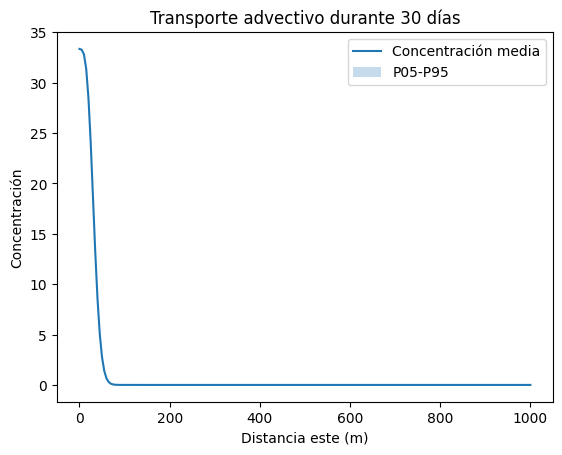

In [2]:
modelo = SoilModelFacade(simulations=1000, seed=42)

resultado = modelo.resolve(
    strategy="advection",
    area=100,
    volume=2000,
    concentration=500,
    porosity=0.3,
    velocity=1,
    length=1000,
    width=500,
    days=30,
    dx=5,
    dt=0.1
)

print("Extensión media de la pluma:", resultado["extent_mean"], "m")

plt.plot(resultado["x"], resultado["mean"], label="Concentración media")
plt.fill_between(resultado["x"], resultado["p05"], resultado["p95"], alpha=0.25, label="P05-P95")
plt.xlabel("Distancia este (m)")
plt.ylabel("Concentración")
plt.title("Transporte advectivo durante 30 días")
plt.legend()
plt.show()

Extensión media: 29.913325347012165 m


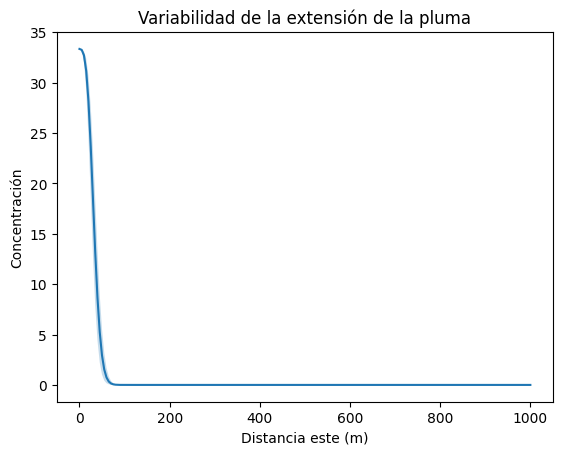

In [3]:
resultado = modelo.resolve(
    strategy="advection",
    area=100,
    volume=2000,
    concentration=500,
    porosity=0.3,
    velocity={"distribution": "normal", "mean": 1, "std": 0.1},
    length=1000,
    width=500,
    days=30,
    dx=5,
    dt=0.1
)

print("Extensión media:", resultado["extent_mean"], "m")

plt.plot(resultado["x"], resultado["mean"])
plt.fill_between(resultado["x"], resultado["p05"], resultado["p95"], alpha=0.25)
plt.xlabel("Distancia este (m)")
plt.ylabel("Concentración")
plt.title("Variabilidad de la extensión de la pluma")
plt.show()